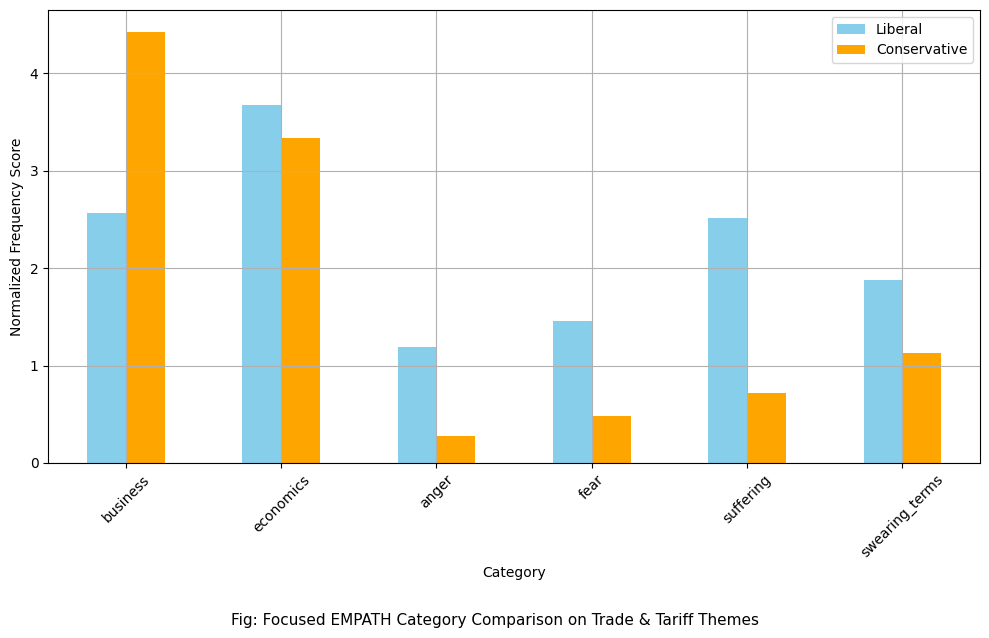

In [11]:
from empath import Empath
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

# Load your CSVs
lib_df = pd.read_csv('C:/Users/samik/Downloads/SMM/Paper2/LiberalsData/Vader_score_Lib.csv')
con_df = pd.read_csv('C:/Users/samik/Downloads/SMM/Paper2/ConservativesData/Vader_score_Con.csv')

# Initialize Empath
lexicon = Empath()

# Define priority categories
priority_categories = ['business', 'economics', 'criticism', 'inflation', 'anger', 'fear', 'suffering', 'swearing_terms']

# Function to extract only priority EMPATH categories
def extract_priority_empath_categories(text_series, priority_list):
    category_counter = defaultdict(float)
    for text in text_series.dropna():
        categories = lexicon.analyze(text, normalize=True)
        for cat in priority_list:
            if cat in categories:
                category_counter[cat] += categories[cat]
    return pd.Series(category_counter)

# Apply for liberals and conservatives
lib_priority = extract_priority_empath_categories(lib_df['Text'], priority_categories)
con_priority = extract_priority_empath_categories(con_df['Text'], priority_categories)

# Combine into DataFrame
empath_priority_df = pd.DataFrame({
    'Liberal': lib_priority,
    'Conservative': con_priority
}).fillna(0)

# Plotting
empath_priority_df.plot(kind='bar', figsize=(10, 6), color=['skyblue', 'orange'])
plt.xlabel('Category')
plt.ylabel('Normalized Frequency Score')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.figtext(0.5, -0.05, 'Fig: Focused EMPATH Category Comparison on Trade & Tariff Themes',
            wrap=True, horizontalalignment='center', fontsize=11)
plt.show()
